In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:45951")
client

<Client: 'tcp://127.0.0.1:45951' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).chunk({"time":4,"level":1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   # level=slice(1,None)
                                  ).chunk({"time":4,"level":1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>

[2.13 3.85 5.26 6.27] <xarray.DataArray (lp1: 4)> Size: 32B
array([1002.13, 1001.72, 1001.41, 1001.01])
Coordinates:
  * lp1      (lp1) float64 32B 0.5 1.5 2.5 3.5
Fitted Equation: y = 0.0118 * e^(0.2000 * x) + -0.0334


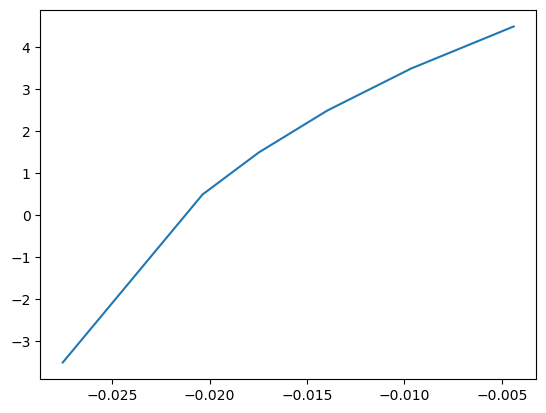

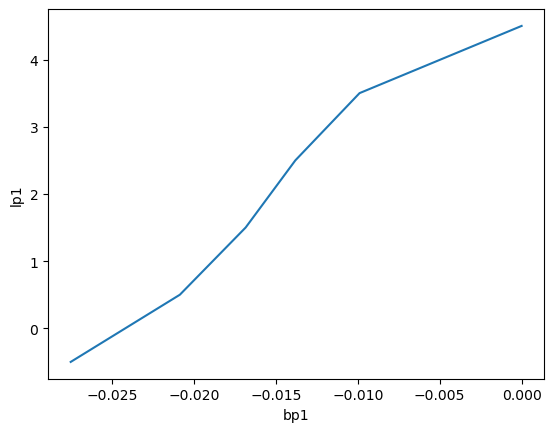

(<xarray.Dataset> Size: 550GB
 Dimensions:  (time: 630, level: 5, y: 2048, x: 4096, lp1: 6, yG: 2047, xG: 4095)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
   * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
 Data variables:
     h        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     Z        (time, level, y, x) float32

In [5]:
rho0 = 1e3
drho = np.array([2.13, 1.72, 1.41, 1.01,])
rho = xr.DataArray(drho + rho0, 
                   dims="lp1",
                   coords={"lp1":np.array([0.5,1.5,2.5,3.5,])}
                  )
print(np.cumsum(drho), rho)

# log_y = np.log(rho)

# # 2. Fit a 1st-degree polynomial (linear fit: y = mx + c)
# # Returns [B, ln(A)]
# coefficients = np.polyfit(rho.lp1.data, log_y, 1)

# # 3. Extract the parameters
# B = coefficients[0]
# A = np.exp(coefficients[1])

# print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x)")

# rp1 = np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5)),]),rho.data)),
#                     np.array([A*np.exp(B*(4.5)),]) 
#                    ))

g = 9.8
b = -g*(rho - rho0) / rho0

B = 0.2
def exp_func(x, a, c):
    return a * np.exp(B * x) + c

initial_guess = [1, -1e-2]
popt, pcov = curve_fit(exp_func, b.lp1.values, b.values, p0=initial_guess)

# 3. Extract parameters
A, C = popt
print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x) + {C:.4f}")
plt.plot(A*np.exp(B*np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))+C, 
         np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))
plt.show()

# bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
#                     np.array([A*np.exp(B*(4.5))+C,]) 
#                    )), dims="lp1", 
#                    coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
#                   )
bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
                    np.array([0.,]) 
                   )), dims="lp1", 
                   coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                  )

ds2 = ds.copy()

ssh = xr.open_zarr(op.join(ddir,"SW/48/SSH.zarr")).ssh
# dszl = xr.open_zarr(op.join(ddir,"SW/48/Zl.zarr"))
# dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr"))
dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr")
                  ).Z.transpose("time","level","y","x"
                               ).to_dataset(name="Z")
dsz["Zl"] = xr.open_zarr(op.join(ddir,"SW/48/Zl.zarr")
                        ).Zl.transpose("time","lp1","y","x")
ds2["Z"] = dsz.Z.transpose("time","level","y","x").chunk({"level":-1})
Zp1 = xr.concat([dsz.Zl, xr.DataArray(ssh.data[:,np.newaxis,:,:],
                                    dims=dsz.Zl.dims, 
                                    coords={"lp1":np.array([4.5,])})
                ], "lp1")
ds2["Zp1"] = Zp1.transpose("time","lp1","y","x").chunk({"lp1":-1})
ds2["bp1"] = bp1
ds2.bp1.plot(y="lp1")
plt.show()

llo, lla = np.meshgrid(ds.x, ds.y)
xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
                  coords={"y":ds.y.data,
                          "xG":.5*(ds.x.data[1:]+ds.x.data[:-1])}
                 )
yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
                  coords={"yG":.5*(ds.y.data[1:]+ds.y.data[:-1]),
                          "x":ds.x.data}
                 )
ds2.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds2.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))

grid = Grid(ds2, 
            padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1"}
                   })

ds2, grid

In [6]:
# dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr")
#                   ).Z.transpose("time","level","y","x"
#                                ).to_dataset(name="Z")
# dsz["Zl"] = xr.open_zarr(op.join(ddir,"SW/48/Zl.zarr")
#                         ).Zl.transpose("time","lp1","y","x")
dsz.coords["yG"] = ("yG",.5*(ds2.y.data[1:]+ds2.y.data[:-1]))
dsz.coords["xG"] = ("xG",.5*(ds2.x.data[1:]+ds2.x.data[:-1]))
dsz.coords["li"] = ("li",ds2.lp1.isel(lp1=slice(1,-1)).data)

gridz = Grid(dsz, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
             autoparse_metadata=False,
             coords={"X": {"center": "x", "inner": "xG"},
                     "Y": {"center": "y", "inner": "yG"},
                     "Z": {"center": "level", "left": "lp1", "inner": "li"}
                    })
dsz, gridz

(<xarray.Dataset> Size: 211GB
 Dimensions:  (level: 5, time: 630, x: 4096, y: 2048, lp1: 5, yG: 2047,
               xG: 4095, li: 4)
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * lp1      (lp1) float64 40B -0.5 0.5 1.5 2.5 3.5
   * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
   * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
   * li       (li) float64 32B 0.5 1.5 2.5 3.5
 Data variables:
     Z        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 4, 128, 256), meta=np.ndarray>
     Zl       (time, lp1, y, x) float32 106GB dask.array<chunksize=(4, 5, 128, 256), meta=np.ndarray>,
 <xgcm.Grid>
 X Axis (not periodic, padding='extend'):
   * center   x --> inner


(<xarray.DataArray (time: 630, level: 5, y: 2048, x: 4096)> Size: 211GB
 dask.array<truediv, shape=(630, 5, 2048, 4096), dtype=float64, chunksize=(4, 1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<truediv, shape=(4, 2048, 4096), dtype=float64, chunksize=(1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<mul, shape=(4, 2048, 4096), dtype=floa

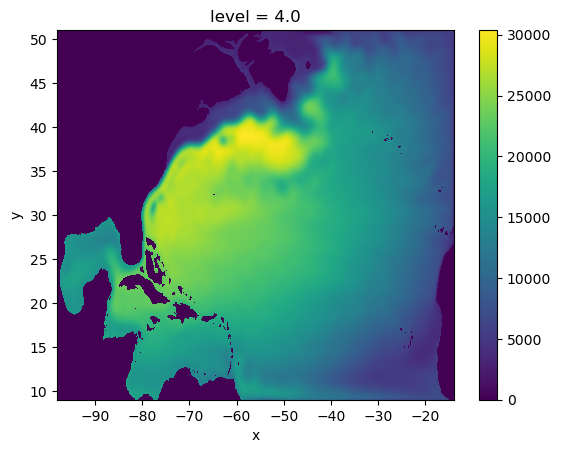

In [16]:
dsm = xr.open_zarr(op.join(ddir,"SW/48/Montgomery.zarr"))

dspp = xr.open_zarr(op.join(ddir,"SW/48/TWA/Upp.zarr"))
dszp = dsz - dsz.mean("time")
mp = dsm.m - dsm.m.mean("time")

dsb = xr.open_zarr(op.join(ddir,"SW/48/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256}
                         )

rho0 = 1e3; g = 9.8
dr = np.array([.41,.31,.40,1.01])
gp = np.concatenate((g*dr/rho0, np.array([10.,])))
_b = grid.interp(ds2.bp1,"Z",padding="extend"
                ).isel(level=slice(1,-1))
b = xr.concat([_b.copy(), 
               xr.DataArray(np.array([_b.isel(level=-1).data+gp[-2]]), 
                            dims=["level"],
                            coords={"level":np.array([ds2.level[-1].values,])}
                           )
              ], "level"
             ).sortby("level")
b = xr.concat([xr.DataArray(np.array([_b.isel(level=0).data-gp[0]]), 
                            dims=["level"],
                            coords={"level":np.array([ds2.level[0].values,])}
                           ),
               b], "level"
             ).sortby("level")

_bp1 = ds2.bp1.isel(lp1=slice(1,-1))
bp1 = xr.concat([_bp1.copy(), 
                 xr.DataArray(np.array([_bp1.isel(lp1=-1)
                                        + 2*(b.isel(level=-1)-_bp1.isel(lp1=-1)
                                            ).data,
                                       ]),
                              dims=["lp1"], 
                              coords={"lp1":np.array([ds2.lp1[-1].values,]),})
                ], "lp1").sortby("lp1")
bp1 = xr.concat([xr.DataArray(np.array([_bp1.isel(lp1=0)
                                        + 2*(b.isel(level=0)-_bp1.isel(lp1=0)
                                            ).data,
                                       ]),
                              dims=["lp1"], 
                              coords={"lp1":np.array([ds2.lp1[0].values,]),}), 
                 bp1
                ], "lp1").sortby("lp1")

sig = (ds2.h
       / grid.diff(bp1.chunk({"lp1":-1}),"Z",padding="extend")
      )
sigb = (dsb.hbar 
        / grid.diff(bp1.chunk({"lp1":-1}),
                    "Z",padding="extend"))
sigb.isel(level=-1).plot(rasterized=True)

vh_x = (grid.interp(grid.diff((dsb.uhat*dsb.hbar).chunk({"x":-1}), 
                              "X", padding="extend"
                             ) / xxG, "X", padding="extend"
                   ) / dsb.hbar
       )
uh_y = (grid.interp(grid.diff((dsb.vhat*dsb.hbar).chunk({"y":-1}), 
                              "Y", padding="extend"
                             ) / yyG, "Y", padding="extend"
                   ) / dsb.hbar
       )
cori = gsw.f(dsb.y)
Pih = (sigb**-1
       * (cori + vh_x - uh_y)
      )
sig, sigb, Pih

In [8]:
dsep = xr.open_zarr(op.join(ddir,"SW/48/TWA/E-P.zarr"))

dsep.coords["yG"] = ("yG",.5*(ds2.y.data[1:]+ds2.y.data[:-1]))
dsep.coords["xG"] = ("xG",.5*(ds2.x.data[1:]+ds2.x.data[:-1]))
dsep.coords["li"] = ("li",ds2.lp1.isel(lp1=slice(1,None)).data)

gridp = Grid(dsep, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
             autoparse_metadata=False,
             coords={"X": {"center": "x", "inner": "xG"},
                     "Y": {"center": "y", "inner": "yG"},
                     "Z": {"center": "level", "outer": "li"}
                    })
dsep

<xarray.Dataset> Size: 1GB
Dimensions:  (level: 4, y: 2048, x: 4096, yG: 2047, xG: 4095, li: 5)
Coordinates:
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * yG       (yG) float32 8kB 9.021 9.041 9.062 9.082 ... 50.94 50.96 50.98
  * xG       (xG) float32 16kB -97.98 -97.96 -97.94 ... -14.06 -14.04 -14.02
  * li       (li) float64 40B 0.5 1.5 2.5 3.5 4.5
Data variables:
    E00      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    E11      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    E20      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    E21      (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    Ecros    (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    Ediag    (level, y, x) float32 134MB dask.array<chunksize=(2, 128, 256), meta=np.ndarray>

In [9]:
il = -2
Ju0_x = gridp.interp(gridp.diff(dsep.E00.chunk({"x":-1}), "X", padding="extend")
                     / xxG, "X", padding="extend"
                    )
Ju0 = ((Ju0_x 
         + gridp.interp(gridp.diff(dsep.Ecros.chunk({"y":-1}), "Y", padding="extend")
                        / yyG, "Y", padding="extend"
                       )
        ) * sigb**-1).isel(level=-il).fillna(0.)
Ju1 = (gridp.interp(gridp.diff(dsep.Ediag.chunk({"x":-1}), "X", padding="extend")
                     / xxG, "X", padding="extend"
                    ) * sigb**-1).isel(level=-il).fillna(0.)
# Ju2 = -((gridp.diff(dsep.E20, "Z", padding="extend"
#                    ) / grid.diff(ds2.b, "Z", padding="extend")
#         ) * sigb**-1).isel(level=-2).fillna(0.)
# Ju2 = -((gridp.interp(gridp.diff(dsep.E20.chunk({"level":-1}), "Z", padding="extend"), 
#                       "Z", padding="extend")
#          / gridp.diff(dsep.b, "Z", padding="extend")
#         ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Ju2 = (gridp.interp(gridp.diff(dsep.E20.chunk({"level":-1}), 
                                "Z", padding="extend")
                     / gridp.diff(b.isel(level=slice(1,None)).chunk({"level":-1}), 
                                  "Z", padding="extend"
                                 ), 
                     "Z", padding="extend")
        * sigb**-1).isel(level=-il).fillna(0.)

Jv0_x = gridp.interp(gridp.diff(dsep.Ecros.chunk({"x":-1}), "X", padding="extend")
                     / xxG, "X", padding="extend"
                    )
Jv0 = ((Jv0_x 
         + gridp.interp(gridp.diff(dsep.E11.chunk({"y":-1}), "Y", padding="extend")
                        / yyG, "Y", padding="extend"
                       )
        ) * sigb**-1).isel(level=-il).fillna(0.)
Jv1 = (gridp.interp(gridp.diff(dsep.Ediag.chunk({"y":-1}), "Y", padding="extend")
                     / yyG, "Y", padding="extend"
                    ) * sigb**-1).isel(level=-il).fillna(0.)
# Jv2 = -((gridp.diff(dsep.E21, "Z", padding="extend"
#                    ) / grid.diff(ds2.b, "Z", padding="extend")
#         ) * sigb**-1).isel(level=-2).fillna(0.)
# Jv2 = -((gridp.interp(gridp.diff(dsep.E21.chunk({"level":-1}), "Z", padding="extend"), 
#                      "Z", padding="extend") 
#          / gridp.diff(dsep.b, "Z", padding="extend")
#         ) * sigb**-1).isel(level=-2).fillna(0.).compute()
Jv2 = (gridp.interp(gridp.diff(dsep.E21.chunk({"level":-1}), 
                                "Z", padding="extend")
                     / gridp.diff(b.isel(level=slice(1,None)).chunk({"level":-1}), 
                                  "Z", padding="extend"
                                 ), 
                     "Z", padding="extend") 
        * sigb**-1).isel(level=-il).fillna(0.)

Ju = Ju0 + Ju1 + Ju2
Jv = Jv0 + Jv1 + Jv2

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(


In [10]:
Fu = (Jv * sigb.isel(level=-il)**-1).fillna(0.).compute()
Fv = (-Ju * sigb.isel(level=-il)**-1).fillna(0.).compute()

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 128.97 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 128.96 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [11]:
sshb = ssh.mean("time").compute()

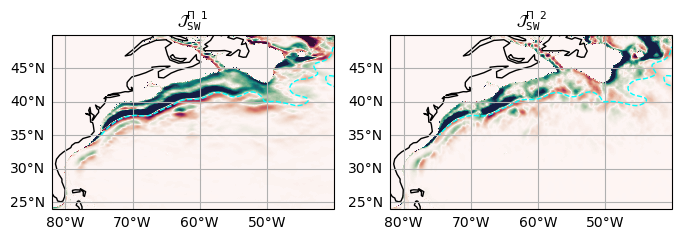

In [32]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure(figsize=(8,4))
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())

ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')

gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False

ax1.pcolormesh(dsb.x, dsb.y, Fu, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-.8e-10, vmax=.8e-10,
              )
ax2.pcolormesh(dsb.x, dsb.y, Fv, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-.8e-10, vmax=.8e-10,
              )

ax1.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="cyan", linestyles="dashed", linewidths=1)
ax2.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="cyan", linestyles="dashed", linewidths=1)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_title(r"${\mathcal{J}^{\Pi}_{\tt SW}}^1$", 
              fontsize=11)
ax2.set_title(r"${\mathcal{J}^{\Pi}_{\tt SW}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_SW-%snd.pdf" % np.abs(il)), dpi=200)

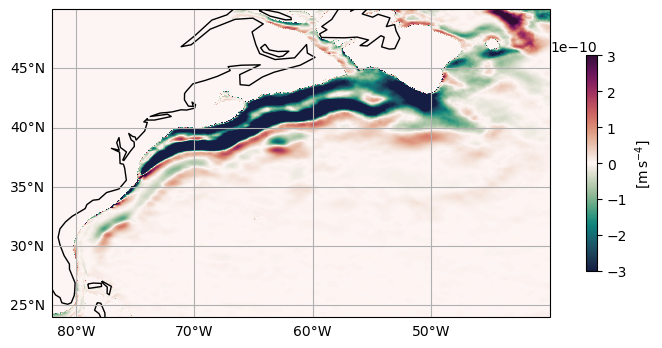

In [29]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure(figsize=(9.5,4))
ax6 = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax6.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax6.coastlines(resolution='110m')
gl6 = ax6.gridlines(draw_labels=True)
gl6.top_labels = False
gl6.right_labels = False

im = ax6.pcolormesh(dsb.x, dsb.y, Fu, 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-3e-10, vmax=3e-10,
               rasterized=True)

cb = fig.colorbar(im, ax=ax6, shrink=.7)
cb.set_label(r"[m$\,$s$^{-4}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_SW_cbar.pdf"))

In [13]:
divJ = (grid.interp(gridp.diff(Jv.chunk({"x":-1}),"X",padding="extend")
                    / xxG,"X",padding="extend")
        + grid.interp(gridp.diff(-Ju.chunk({"y":-1}),"Y",padding="extend")
                      / yyG,"Y",padding="extend")
       ) * sigb.isel(level=-il)**-1
divJ

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/dask/array/core.py:5200: PerformanceWarning: Increasing number of chunks by factor of 16
  result = blockwise(


<xarray.DataArray (y: 2048, x: 4096)> Size: 67MB
dask.array<mul, shape=(2048, 4096), dtype=float64, chunksize=(128, 256), chunktype=numpy.ndarray>
Coordinates:
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
    level    float32 4B 3.0

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 257.92 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


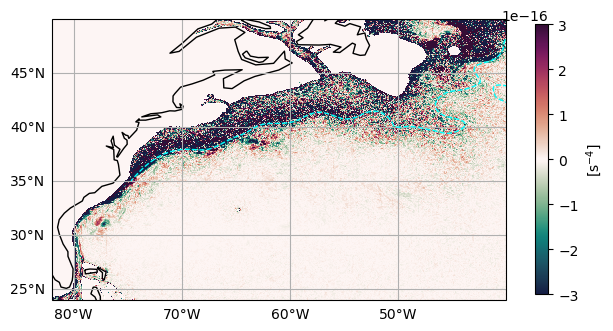

In [16]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure()
fig.set_tight_layout(True)
ax1 = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax1.coastlines(resolution='110m')
gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False

im = ax1.pcolormesh(dsb.x, dsb.y, divJ.fillna(0.), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-3e-16, vmax=3e-16,
               # rasterized=True
                   )

ax1.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="cyan", linestyles="dashed", linewidths=1)

ax1.set_rasterized(True)

cb = fig.colorbar(im, ax=ax1, shrink=.6)
cb.set_label(r"[s$^{-4}$]")

plt.savefig(op.join(ddir,"Figs/divPVflux_SW_cbar.pdf"))

$$\widehat{{\bf u}''\Pi''}$$

In [14]:
dsPp = xr.open_zarr(op.join(ddir,"SW/48/TWA/uppPipp.zarr"))
dsPp

<xarray.Dataset> Size: 537MB
Dimensions:    (level: 4, y: 2048, x: 4096)
Coordinates:
  * level      (level) float32 16B 1.0 2.0 3.0 4.0
  * y          (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.95 50.97 50.99
  * x          (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    uppPpphat  (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    vppPpphat  (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>

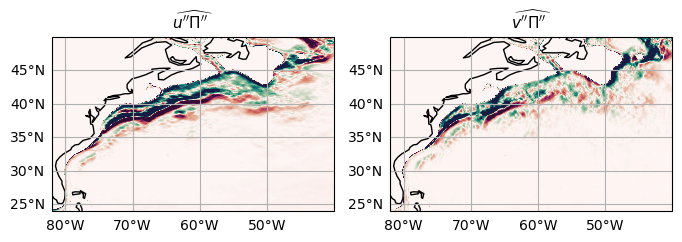

In [31]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure(figsize=(8,4))
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())

ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')

gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False

ax1.pcolormesh(dsb.x, dsb.y, dsPp.uppPpphat.isel(level=-2).fillna(0.), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-.8e-10, vmax=.8e-10,
               rasterized=True)
ax2.pcolormesh(dsb.x, dsb.y, dsPp.vppPpphat.isel(level=-2).fillna(0.), 
               cmap=cmocean.cm.curl,
               # cmap="RdBu_r",
               vmin=-.8e-10, vmax=.8e-10,
               rasterized=True)

ax1.set_title(r"$\widehat{u''\Pi''}$", 
              fontsize=11)
ax2.set_title(r"$\widehat{v''\Pi''}$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVppflux_SW.pdf"), dpi=200)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 64.05 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 64.05 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


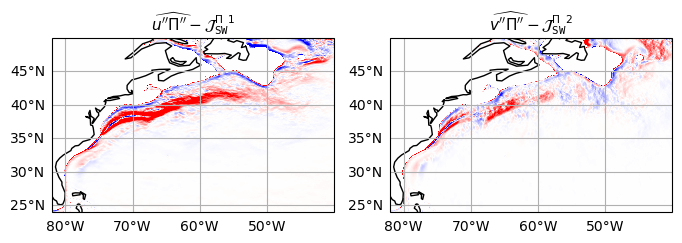

In [32]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure(figsize=(8,4))
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())

ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')

gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False

ax1.pcolormesh(dsb.x, dsb.y, 
               dsPp.uppPpphat.isel(level=-2).fillna(0.) - Fu, 
               # cmap=cmocean.cm.curl,
               cmap="bwr",
               vmin=-.6e-10, vmax=.6e-10,
               rasterized=True)
ax2.pcolormesh(dsb.x, dsb.y, 
               dsPp.vppPpphat.isel(level=-2).fillna(0.) - Fv, 
               # cmap=cmocean.cm.curl,
               cmap="bwr",
               vmin=-.8e-10, vmax=.8e-10,
               rasterized=True)

ax1.set_title(r"$\widehat{u''\Pi''} - {\mathcal{J}^{\Pi}_{\tt SW}}^1$", 
              fontsize=11)
ax2.set_title(r"$\widehat{v''\Pi''} - {\mathcal{J}^{\Pi}_{\tt SW}}^2$", 
              fontsize=11)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/PVflux_SW-diff.pdf"), dpi=200)

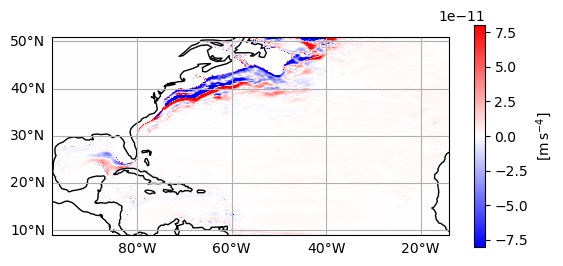

In [33]:
fig = plt.figure()
ax6 = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax6.set_extent([dsb.x.min(), dsb.x.max(), dsb.y.min(), dsb.y.max()], 
              crs=ccrs.PlateCarree())
ax6.coastlines(resolution='110m')
gl6 = ax6.gridlines(draw_labels=True)
gl6.top_labels = False
gl6.right_labels = False

im = ax6.pcolormesh(dsb.x, dsb.y, dsPp.uppPpphat.isel(level=-2).fillna(0.), 
               # cmap=cmocean.cm.curl,
               cmap="bwr",
               vmin=-.8e-10, vmax=.8e-10,
               rasterized=True)

cb = fig.colorbar(im, ax=ax6, shrink=.6)
cb.set_label(r"[m$\,$s$^{-4}$]")
plt.savefig(op.join(ddir,"Figs/PVflux_SW-diff_cbar.pdf"), dpi=200)

$${\bf J}^\Pi / \nabla\Pi^\sharp$$

In [20]:
Pih_x = grid.interp(grid.diff(Pih.isel(level=-il).chunk({"x":-1}), 
                              "X", padding="extend")
                    / xxG, "X", padding="extend"
                   )
Pih_y = grid.interp(grid.diff(Pih.isel(level=-il).chunk({"y":-1}), 
                              "Y", padding="extend")
                    / yyG, "Y", padding="extend"
                   )
ratx = Fu / Pih_x
raty = Fv / Pih_y
ratx, raty

(<xarray.DataArray (y: 2048, x: 4096)> Size: 67MB
 dask.array<divide, shape=(2048, 4096), dtype=float64, chunksize=(128, 4096), chunktype=numpy.ndarray>
 Coordinates:
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
     level    float32 4B 3.0,
 <xarray.DataArray (y: 2048, x: 4096)> Size: 67MB
 dask.array<divide, shape=(2048, 4096), dtype=float64, chunksize=(2048, 256), chunktype=numpy.ndarray>
 Coordinates:
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
     level    float32 4B 3.0)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 256.66 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 256.64 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


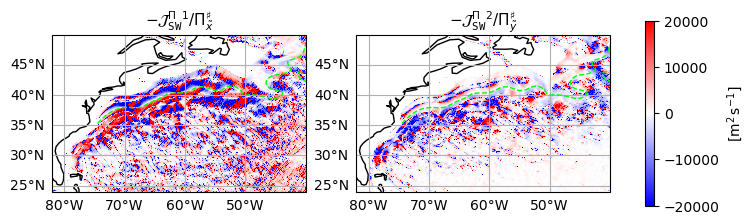

In [29]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

# fig = plt.figure(figsize=(9,4))
# ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
# ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
fig, axes = plt.subplots(
    figsize=(9,4), nrows=1, ncols=2,
    subplot_kw={"projection": ccrs.PlateCarree()},
)
ax1, ax2 = axes

ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')

gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False

im = ax1.pcolormesh(dsb.x, dsb.y, 
               -ratx, 
               # cmap=cmocean.cm.curl,
               cmap="bwr",
               vmin=-2e4, vmax=2e4,
              )
ax2.pcolormesh(dsb.x, dsb.y, 
               -raty, 
               # cmap=cmocean.cm.curl,
               cmap="bwr",
               vmin=-2e4, vmax=2e4,
              )

ax1.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax2.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="lime", linestyles="dashed", linewidths=1)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

ax1.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^1/\Pi^\sharp_\tilde{x}$", 
              fontsize=11)
ax2.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^2/\Pi^\sharp_\tilde{y}$", 
              fontsize=11)

cb = fig.colorbar(im, ax=axes, shrink=.6)
cb.set_label(r"[m$^2\,$s$^{-1}$]")

plt.savefig(op.join(ddir,"Figs/PV_kappa.pdf"), dpi=200)